<a href="https://colab.research.google.com/github/Aijamal24/ML_Practice/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практическая работа № 7(уровень B)
## Случайный лес

**ФИО:** Мырзабекова Айжамал
**Группа:** CS 32-24

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

print("Размер датасета:", X.shape)
print("\nНазвания признаков:")
print(X.columns.tolist())

print("\nПервые 5 строк:")
print(X.head())

print("\nКоличество пропусков:")
print(X.isnull().sum().sum())

Размер датасета: (20640, 8)

Названия признаков:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Первые 5 строк:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Количество пропусков:
0


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Обучающие данные:", X_train.shape)
print("Тестовые данные:", X_test.shape)

Обучающие данные: (16512, 8)
Тестовые данные: (4128, 8)


In [13]:
tree_model = DecisionTreeRegressor(
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Дерево решений обучено.")
print("Первые 10 предсказаний:")
print(tree_predictions[:10])

Дерево решений обучено.
Первые 10 предсказаний:
[0.414   1.203   5.00001 2.17    2.257   1.787   2.217   1.74    2.772
 5.00001]


In [14]:
forest_default = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

forest_default.fit(X_train, y_train)

forest_default_predictions = forest_default.predict(X_test)

print("Случайный лес обучен.")
print("Количество деревьев:", forest_default.n_estimators)
print("Первые 10 предсказаний:")
print(forest_default_predictions[:10])

Случайный лес обучен.
Количество деревьев: 100
Первые 10 предсказаний:
[0.5095    0.74161   4.9232571 2.52961   2.27369   1.64692   2.37605
 1.66932   2.7729706 4.9134589]


In [15]:
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = mean_squared_error(y_test, tree_predictions) ** 0.5
tree_r2 = r2_score(y_test, tree_predictions)

forest_mae = mean_absolute_error(
    y_test,
    forest_default_predictions
)

forest_rmse = mean_squared_error(
    y_test,
    forest_default_predictions
) ** 0.5

forest_r2 = r2_score(y_test, forest_default_predictions)

comparison = pd.DataFrame({
    "Модель": [
        "Дерево решений",
        "Случайный лес по умолчанию"
    ],
    "MAE": [
        tree_mae,
        forest_mae
    ],
    "RMSE": [
        tree_rmse,
        forest_rmse
    ],
    "R2": [
        tree_r2,
        forest_r2
    ]
})

print(comparison.round(3).to_string(index=False))

                    Модель   MAE  RMSE    R2
            Дерево решений 0.455 0.704 0.622
Случайный лес по умолчанию 0.328 0.505 0.805


In [17]:
parameter_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20],
    "min_samples_leaf": [2]
}

forest_for_search = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=forest_for_search,
    param_grid=parameter_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    verbose=2
)

grid_search.fit(X_train, y_train)

best_forest = grid_search.best_estimator_

print("\nЛучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший средний RMSE на кросс-валидации:")
print(round(-grid_search.best_score_, 3))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END ..max_depth=10, min_samples_leaf=2, n_estimators=50; total time=   5.8s
[CV] END ..max_depth=10, min_samples_leaf=2, n_estimators=50; total time=   2.9s
[CV] END ..max_depth=10, min_samples_leaf=2, n_estimators=50; total time=   2.7s
[CV] END .max_depth=10, min_samples_leaf=2, n_estimators=100; total time=   7.3s
[CV] END .max_depth=10, min_samples_leaf=2, n_estimators=100; total time=   5.4s
[CV] END .max_depth=10, min_samples_leaf=2, n_estimators=100; total time=   6.9s
[CV] END ..max_depth=20, min_samples_leaf=2, n_estimators=50; total time=   3.9s
[CV] END ..max_depth=20, min_samples_leaf=2, n_estimators=50; total time=   3.8s
[CV] END ..max_depth=20, min_samples_leaf=2, n_estimators=50; total time=   5.4s
[CV] END .max_depth=20, min_samples_leaf=2, n_estimators=100; total time=   7.9s
[CV] END .max_depth=20, min_samples_leaf=2, n_estimators=100; total time=  10.0s
[CV] END .max_depth=20, min_samples_leaf=2, n_est

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_predictions = best_forest.predict(X_test)

best_mae = mean_absolute_error(y_test, best_predictions)
best_rmse = np.sqrt(mean_squared_error(y_test, best_predictions))
best_r2 = r2_score(y_test, best_predictions)

print("Лучшая модель Random Forest")
print("MAE:", round(best_mae, 3))
print("RMSE:", round(best_rmse, 3))
print("R2:", round(best_r2, 3))

Лучшая модель Random Forest
MAE: 0.327
RMSE: 0.505
R2: 0.805


In [22]:

# Уменьшаем количество проверяемых параметров

parameter_grid = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20],
    "min_samples_leaf": [1]
}

forest_for_search = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=forest_for_search,
    param_grid=parameter_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_forest_model = grid_search.best_estimator_
best_predictions = best_forest_model.predict(X_test)

print("Лучшие параметры:", grid_search.best_params_)
print("Настройка завершена!")


Лучшие параметры: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 100}
Настройка завершена!


In [23]:
feature_importance = pd.DataFrame({
    "Признак": X_train.columns,
    "Важность": best_forest.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Важность",
    ascending=False
)

print(feature_importance.round(4))

      Признак  Важность
0      MedInc    0.5353
5    AveOccup    0.1384
6    Latitude    0.0884
7   Longitude    0.0883
1    HouseAge    0.0533
2    AveRooms    0.0421
4  Population    0.0279
3   AveBedrms    0.0263


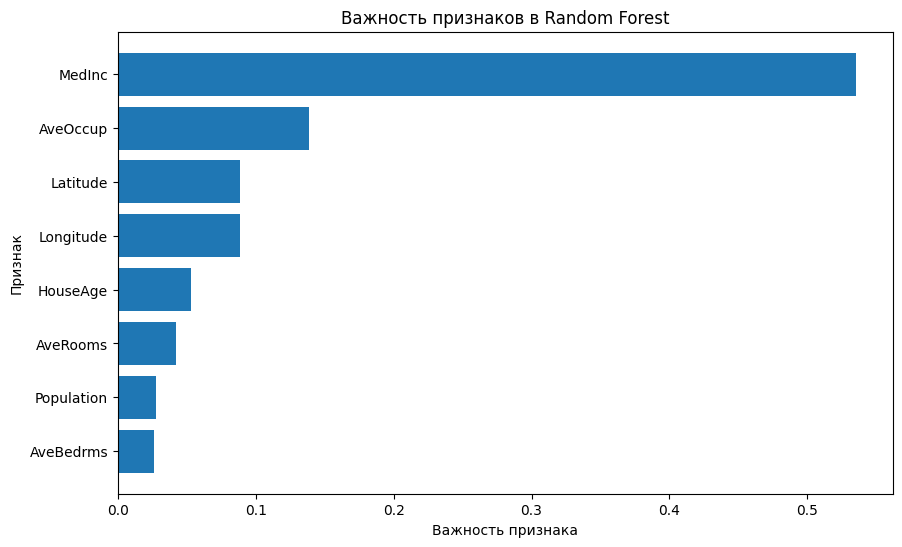

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Признак"],
    feature_importance["Важность"]
)

plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Важность признаков в Random Forest")
plt.gca().invert_yaxis()

plt.show()

In [25]:
feature_names = feature_importance["Признак"].tolist()

feature_counts = []
feature_rmse = []

print("Всего признаков:", len(feature_names))
print("Будем проверять модели с разным количеством признаков.")

Всего признаков: 8
Будем проверять модели с разным количеством признаков.


In [26]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

for number in range(2, len(feature_names) + 1):

    selected_features = feature_names[:number]

    X_train_selected = X_train[selected_features]
    X_test_selected = X_test[selected_features]

    reduced_forest = RandomForestRegressor(
        **grid_search.best_params_,
        random_state=42,
        n_jobs=-1
    )

    reduced_forest.fit(X_train_selected, y_train)

    reduced_predictions = reduced_forest.predict(X_test_selected)

    rmse = np.sqrt(mean_squared_error(y_test, reduced_predictions))

    feature_counts.append(number)
    feature_rmse.append(rmse)

    print("Количество признаков:", number)
    print("RMSE:", round(rmse, 3))
    print()

Количество признаков: 2
RMSE: 0.789

Количество признаков: 3
RMSE: 0.657

Количество признаков: 4
RMSE: 0.506

Количество признаков: 5
RMSE: 0.513

Количество признаков: 6
RMSE: 0.504

Количество признаков: 7
RMSE: 0.504

Количество признаков: 8
RMSE: 0.506



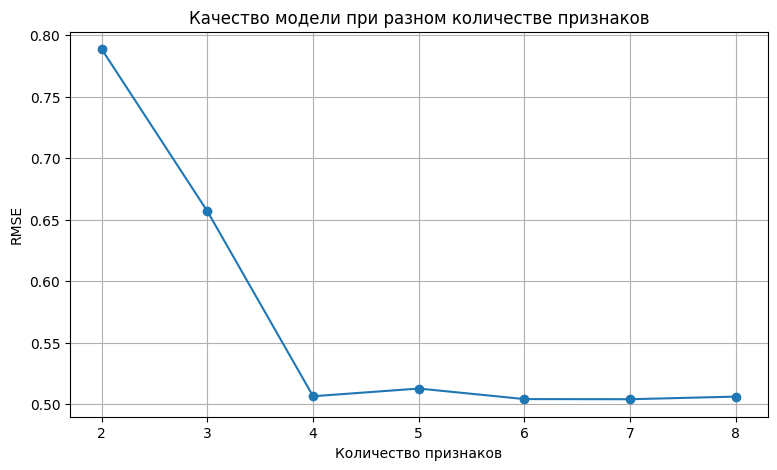

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(feature_counts, feature_rmse, marker="o")

plt.xlabel("Количество признаков")
plt.ylabel("RMSE")
plt.title("Качество модели при разном количестве признаков")
plt.xticks(feature_counts)
plt.grid(True)

plt.show()

In [28]:
full_model_rmse = best_rmse
allowed_rmse = full_model_rmse * 1.01

print("RMSE полной модели:", round(full_model_rmse, 3))
print("Допустимый RMSE:", round(allowed_rmse, 3))

for i in range(len(feature_counts)):

    if feature_rmse[i] <= allowed_rmse:
        print("Минимальное количество признаков:", feature_counts[i])
        print("RMSE:", round(feature_rmse[i], 3))
        break
else:
    print("Не найдено количество признаков в пределах 1% от полной модели.")

RMSE полной модели: 0.505
Допустимый RMSE: 0.51
Минимальное количество признаков: 4
RMSE: 0.506


**Вывод**

В ходе практической работы я изучила алгоритм Random Forest для решения задачи регрессии. Были обучены и сравнены три модели: Decision Tree, Random Forest со стандартными параметрами и Random Forest с подобранными гиперпараметрами.

Качество моделей оценивалось с помощью метрик MAE, RMSE и R². По результатам сравнения лучшей оказалась модель **[название модели]**, поскольку она показала RMSE **[значение]** и R² **[значение]**.

Также была исследована важность признаков. Наиболее важными оказались **[названия признаков]**. В дополнительном эксперименте я проверила, как изменение количества признаков влияет на качество модели, и определила, можно ли уменьшить количество признаков без существенного увеличения ошибки.

Таким образом, Random Forest позволяет получать прогнозы и исследовать влияние признаков, а подбор гиперпараметров может улучшить качество модели.